In [ ]:
import copy
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchmetrics.classification import MulticlassAccuracy, MulticlassConfusionMatrix, MulticlassF1Score

from torchvision import datasets
import torchvision.transforms as transforms

import matplotlib.pyplot as plt


### Preparing Data : 

In [154]:
train_transform = transforms.Compose([
    transforms.RandomAffine(degrees=10, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,))
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,))
])

data_root = './data/FashionMNIST'

train_data = datasets.FashionMNIST(
    root=data_root,
    train=True,
    download=True,
    transform=train_transform,
)
eval_data = datasets.FashionMNIST(
    root=data_root,
    train=True,
    download=True,
    transform=eval_transform,
)
test_data = datasets.FashionMNIST(
    root=data_root,
    train=False,
    download=True,
    transform=eval_transform,
)

len(train_data), len(test_data), len(train_data.classes)

(60000, 10000, 10)

In [155]:
num_classes = len(train_data.classes)
num_classes

10

In [156]:
val_size = int(1 / (len(train_data) / len(test_data)) * len(train_data))
train_size = int(len(train_data) - val_size)

train_size, val_size

(50000, 10000)

In [157]:
seed = 42
generator = torch.Generator().manual_seed(seed)

train_indices, val_indices = random_split(
    range(len(train_data)),
    (train_size, val_size),
    generator=generator,
)
train_data = torch.utils.data.Subset(train_data, train_indices.indices)
val_data = torch.utils.data.Subset(eval_data, val_indices.indices)

len(train_data), len(val_data), len(test_data)

(50000, 10000, 10000)

In [158]:
train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
val_loader = DataLoader(val_data, batch_size=64, shuffle=False)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)

### EDA :

In [159]:
image, label = train_data[0]

print(image.shape)

torch.Size([1, 28, 28])


Label : 9


(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

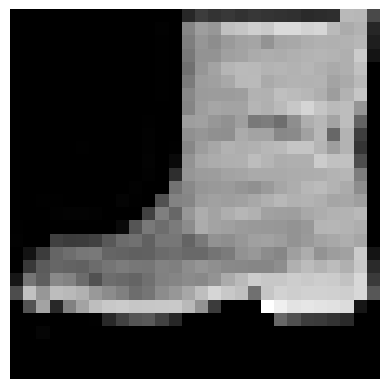

In [160]:
image = image.squeeze()

print(f"Label : {label}")
plt.imshow(image, cmap='grey')
plt.axis('off')

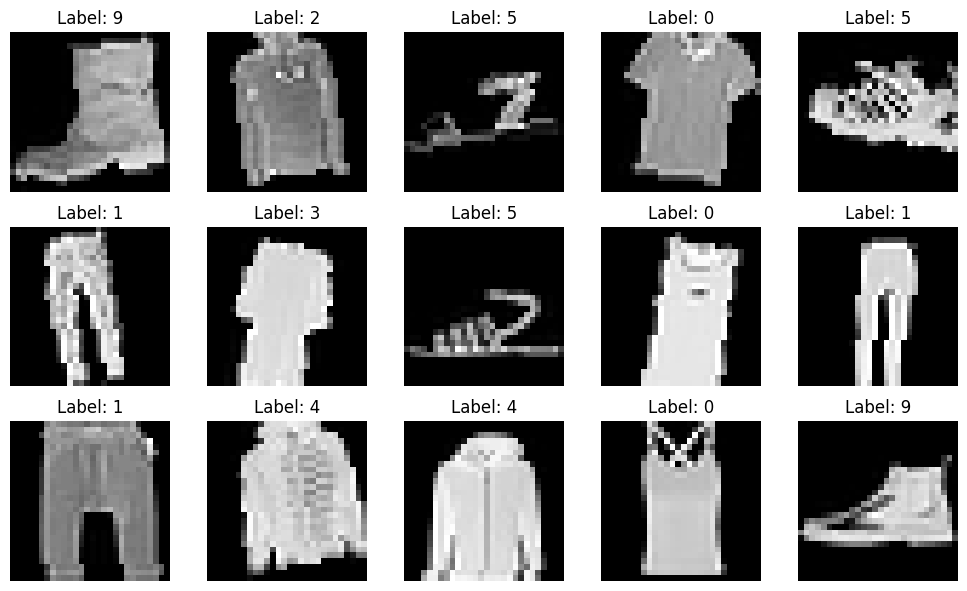

In [161]:
fig, axes = plt.subplots(3, 5, figsize = (10, 6))

for i, ax in enumerate(axes.flat):
	image, label = train_data[i]

	ax.imshow(image.squeeze(), cmap="grey")
	ax.set_title(f"Label: {label}")
	ax.axis("off")

plt.tight_layout()
plt.show()

### Cnn Training :

In [162]:
class Cnn(nn.Module):
	def __init__(self, num_classes):
		super().__init__()
		self.feature_extractor = nn.Sequential(
			nn.Conv2d(1, 32, 3, padding=1),
			nn.BatchNorm2d(32),
			nn.ELU(),
			nn.MaxPool2d(2),
			
			nn.Conv2d(32, 64, 3, padding=1),
			nn.BatchNorm2d(64),
			nn.ELU(),
			nn.MaxPool2d(2),

			nn.Flatten()
		)
		self.classifier = nn.Sequential(
			nn.Linear(64 * 7 * 7, 128),
			nn.BatchNorm1d(128),
			nn.ReLU(),
			nn.Linear(128, num_classes)
		)

	def forward(self, x):
		x = self.feature_extractor(x)
		x = self.classifier(x)
		return x

In [163]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = Cnn(num_classes).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)

In [164]:
num_epochs = 20
best_val_loss = float('inf')
best_state_dict = None

for epoch in range(num_epochs):
	# training :
	model.train()
	train_loss = 0.0

	for images, labels in train_loader:
		images = images.to(device)
		labels = labels.to(device)

		optimizer.zero_grad()

		output = model(images)
		loss = criterion(output, labels)

		train_loss += loss.item()

		loss.backward()
		optimizer.step()

	# validation :
	model.eval()
	val_loss = 0.0

	with torch.no_grad():
		for images, labels in val_loader:
			images = images.to(device)
			labels = labels.to(device)

			output = model(images)
			loss = criterion(output, labels)

			val_loss += loss.item()

	train_loss /= len(train_loader)
	val_loss /= len(val_loader)

	print(f"epoch : {epoch} train_loss : {train_loss:.4f} val_loss : {val_loss:.4f}")

	if val_loss < best_val_loss :
		best_val_loss = val_loss
		best_state_dict = copy.deepcopy(model.state_dict())
		print("saved best model")


epoch : 0 train_loss : 0.5421 val_loss : 0.3616
saved best model
epoch : 1 train_loss : 0.4053 val_loss : 0.3062
saved best model
epoch : 2 train_loss : 0.3632 val_loss : 0.2956
saved best model
epoch : 3 train_loss : 0.3418 val_loss : 0.2941
saved best model
epoch : 4 train_loss : 0.3288 val_loss : 0.2943
epoch : 5 train_loss : 0.3168 val_loss : 0.2588
saved best model
epoch : 6 train_loss : 0.3080 val_loss : 0.2616
epoch : 7 train_loss : 0.3017 val_loss : 0.2422
saved best model
epoch : 8 train_loss : 0.2962 val_loss : 0.2550
epoch : 9 train_loss : 0.2915 val_loss : 0.2590
epoch : 10 train_loss : 0.2860 val_loss : 0.2498
epoch : 11 train_loss : 0.2827 val_loss : 0.2457
epoch : 12 train_loss : 0.2783 val_loss : 0.2328
saved best model
epoch : 13 train_loss : 0.2775 val_loss : 0.2362
epoch : 14 train_loss : 0.2730 val_loss : 0.2201
saved best model
epoch : 15 train_loss : 0.2719 val_loss : 0.2332
epoch : 16 train_loss : 0.2680 val_loss : 0.2225
epoch : 17 train_loss : 0.2697 val_loss :

### Evaluation on Test Data : 

In [165]:
model.load_state_dict(best_state_dict)

<All keys matched successfully>

In [166]:
accuracy = MulticlassAccuracy(num_classes).to(device)
cm = MulticlassConfusionMatrix(num_classes).to(device)
macro_f1 = MulticlassF1Score(num_classes, average='macro').to(device)
micro_f1 = MulticlassF1Score(num_classes, average='micro').to(device)
weighted_f1 = MulticlassF1Score(num_classes, average='weighted').to(device)

model.eval()
test_loss = 0.0

with torch.no_grad():
	for images, labels in test_loader:
		images = images.to(device)
		labels = labels.to(device)

		output = model(images)
		loss = criterion(output, labels)

		accuracy.update(output, labels)
		cm.update(output, labels)
		macro_f1.update(output, labels)
		micro_f1.update(output, labels)
		weighted_f1.update(output, labels)

		test_loss += loss.item()

test_loss /= len(test_loader)
accuracy = accuracy.compute()
cm = cm.compute()
macro_f1 = macro_f1.compute()
micro_f1 = micro_f1.compute()
weighted_f1 = weighted_f1.compute()

print(f"test_loss : {test_loss:.4f}")
print(f"accuracy : {accuracy:.4f}")
print(f" confusion matrix : \n {cm}")
print(f"macro_f1 : {macro_f1:.4f} micro_f1 : {micro_f1:.4f} weighted_f1 : {weighted_f1:.4f}")


test_loss : 0.2291
accuracy : 0.9161
 confusion matrix : 
 tensor([[830,   1,  19,  21,   4,   1, 115,   0,   9,   0],
        [  0, 988,   0,   9,   0,   0,   1,   0,   2,   0],
        [ 11,   2, 879,   9,  45,   0,  54,   0,   0,   0],
        [  7,   6,  11, 930,  23,   0,  23,   0,   0,   0],
        [  1,   0,  51,  28, 886,   0,  34,   0,   0,   0],
        [  0,   0,   0,   0,   0, 981,   0,  12,   0,   7],
        [ 82,   2,  52,  28,  96,   0, 734,   0,   6,   0],
        [  0,   0,   0,   0,   0,   8,   0, 978,   0,  14],
        [  0,   0,   1,   5,   2,   0,   1,   0, 991,   0],
        [  0,   0,   0,   0,   0,   3,   1,  32,   0, 964]], device='cuda:0')
macro_f1 : 0.9158 micro_f1 : 0.9161 weighted_f1 : 0.9158
